# Tallinn Livability Score — Notebook 3: Proximity Factors + Final Score

Computes the four proximity factors — transit stops, groceries, gyms,
green/blue space — and combines them into the final apartment livability
score.

**Energy score is not a scoring factor.** It's shown on the map and in
building attributes for reference, but does not feed into
`final_score_geomean` — see the "Why energy score isn't scored" note in
section 10.

**No OSRM/Docker needed.** `pyrosm` reads the local `estonia-260809.osm.pbf`
directly and builds a walking-network graph; `scipy.sparse.csgraph.dijkstra`
does **multi-source shortest-path** routing — one Dijkstra run per category
(from *every* amenity of that type simultaneously) instead of routing
building-by-building, so all ~7,800 buildings x 4 categories resolves in
well under a second once the graph is built.

Methodology (per the OECD/JRC Handbook + Melbourne Urban Liveability Index):

1. **Network walking distance**, not straight-line — computed on the real
   pedestrian street graph.
2. **Logistic distance-decay** (Higgs et al. 2019 "soft threshold":
   `score = 1 / (1 + exp(k*(d-c)/c))`, k=5, category-specific threshold `c`)
   instead of a binary cutoff or raw distance.
3. **Winsorized min-max normalization** to 0-100 (same helper as notebook 2).
4. **Final aggregation**: geometric mean AND the Mazziotta-Pareto penalized
   mean over the 4 proximity factors, computed side by side as a lightweight
   sensitivity check.


## 1. Imports

In [1]:
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import Point
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra, connected_components
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

pd.set_option("display.max_columns", None)


## 2. CONFIG

In [2]:
DATA_DIR = Path("./data")
INPUT_GPKG    = DATA_DIR / "tallinn_livability_base.gpkg"
BUILDINGS_LAYER = "buildings_scored"       # output of notebook 2
GREEN_BLUE_LAYER = "green_blue_space"      # output of notebook 1
OSM_PBF       = DATA_DIR / "estonia-260809.osm.pbf"
BUS_STOPS_CSV = DATA_DIR / "tallinn_bus_stops.csv"
AMENITIES_CSV = DATA_DIR / "tallinn_gyms_groceries.csv"

OUTPUT_GPKG  = DATA_DIR / "tallinn_livability_base.gpkg"
OUTPUT_LAYER = "buildings_final_score"

METRIC_CRS = "EPSG:3301"   # Estonian National Grid, meters

# Bounding box for network extraction: Tallinn AOI + buffer, so routes near
# the boundary don't get artificially truncated
BBOX = [24.53, 59.34, 24.95, 59.60]   # minx, miny, maxx, maxy (WGS84)

# Cache the extracted network so re-running the notebook doesn't re-parse
# the 121MB pbf every time (~30s) -- only rebuilds if the cache is missing.
NODES_CACHE = DATA_DIR / "_cache_tallinn_walk_nodes.parquet"
EDGES_CACHE = DATA_DIR / "_cache_tallinn_walk_edges.parquet"

# Logistic distance-decay parameters (Higgs et al. 2019 "soft threshold").
# c = distance (m) at which score = 0.5; k = slope steepness.
DECAY_K = 5
DECAY_THRESHOLDS_M = {
    "transit":    400,   # bus/tram stop
    "grocery":    900,   # grocery store
    "gym":       1000,   # fitness facility
    "greenblue":  600,   # green/blue space entry point
}

WINSOR_LOW, WINSOR_HIGH = 0.05, 0.95


## 3. Load inputs

Buildings (with `building_quality_score` from notebook 2), the green/blue
space polygons, bus/tram stops, and gyms/groceries.


In [3]:
buildings = gpd.read_file(INPUT_GPKG, layer=BUILDINGS_LAYER)
green_blue = gpd.read_file(INPUT_GPKG, layer=GREEN_BLUE_LAYER)
stops = pd.read_csv(BUS_STOPS_CSV)
amenities = pd.read_csv(AMENITIES_CSV)
groceries = amenities[amenities["category"] == "grocery"]
gyms = amenities[amenities["category"] == "gym"]

print(f"Buildings: {len(buildings):,}")
print(f"Green/blue polygons: {len(green_blue):,}")
print(f"Bus/tram stops: {len(stops):,}")
print(f"Groceries: {len(groceries):,} | Gyms: {len(gyms):,}")


Buildings: 7,842
Green/blue polygons: 3,128
Bus/tram stops: 1,593
Groceries: 267 | Gyms: 59


## 4. Build (or load cached) walking network

Reads the local OSM pbf directly with `pyrosm` -- no OSRM server, no
Docker, no Overpass API calls. Bounded to Tallinn + a buffer so edge-routing
isn't truncated. Cached to parquet after the first run.


In [4]:
if NODES_CACHE.exists() and EDGES_CACHE.exists():
    nodes = gpd.read_parquet(NODES_CACHE)
    edges = pd.read_parquet(EDGES_CACHE)
    print(f"Loaded cached network: {len(nodes):,} nodes, {len(edges):,} edges")
else:
    from pyrosm import OSM
    t0 = time.time()
    osm = OSM(str(OSM_PBF), bounding_box=BBOX)
    nodes, edges = osm.get_network(network_type="walking", nodes=True)
    nodes = nodes.set_crs(4326).to_crs(METRIC_CRS)
    nodes.to_parquet(NODES_CACHE)
    edges.to_parquet(EDGES_CACHE)
    print(f"Extracted + cached network: {len(nodes):,} nodes, {len(edges):,} edges "
          f"in {time.time()-t0:.1f}s")


Loaded cached network: 277,733 nodes, 305,589 edges


## 5. Build the routing graph

Sparse (undirected, weighted-by-length) graph for `scipy.sparse.csgraph`.
The raw OSM walking network isn't one connected graph -- it's ~1,240
separate components: one giant one (the real, connected street network)
plus ~1,239 tiny fragments of 2-35 nodes each (courtyard/service paths
OSM has geometry for but no tagged connector back to the street grid).
Snapping to the *nearest node of any kind* can land a building on one of
those tiny fragments -- geometrically close, but functionally
unreachable from anywhere. The KD-tree used for snapping is built from
**giant-component nodes only**, so every building/amenity snaps to its
nearest point on the network it can actually be routed through.


In [5]:
node_idx = {nid: i for i, nid in enumerate(nodes["id"])}
n_nodes = len(nodes)

rows = edges["u"].map(node_idx).to_numpy()
cols = edges["v"].map(node_idx).to_numpy()
w = edges["length"].to_numpy()
valid = ~(pd.isna(rows.astype(float)) | pd.isna(cols.astype(float)))
rows, cols, w = rows[valid].astype(int), cols[valid].astype(int), w[valid]

graph = csr_matrix((w, (rows, cols)), shape=(n_nodes, n_nodes))
graph = graph.maximum(graph.T)   # symmetrize -> undirected walking

# Identify the giant connected component -- snapping is restricted to it
n_components, comp_labels = connected_components(graph, directed=False)
giant_label = pd.Series(comp_labels).value_counts().idxmax()
in_giant = comp_labels == giant_label
print(f"{n_components:,} connected components; giant component: "
      f"{in_giant.sum():,} nodes ({in_giant.mean():.1%} of graph)")

node_coords = np.column_stack([nodes.geometry.x, nodes.geometry.y])
giant_node_positions = np.where(in_giant)[0]          # maps tree-index -> real node index
node_tree = cKDTree(node_coords[giant_node_positions])  # KD-tree over giant component ONLY

print(f"Graph: {n_nodes:,} nodes, {graph.nnz:,} directed edge entries after symmetrizing")

def snap_to_network(points_gdf_metric_crs):
    """Returns (snap_distance_m, node_index) for each point, restricted to
    the giant connected component."""
    coords = np.column_stack([points_gdf_metric_crs.geometry.x, points_gdf_metric_crs.geometry.y])
    dist, tree_idx = node_tree.query(coords)
    return dist, giant_node_positions[tree_idx]   # convert back to real node indices

def multisource_distances(source_node_indices):
    """Shortest network distance from ANY source node to every node, in one Dijkstra pass."""
    src = np.unique(source_node_indices)
    return dijkstra(graph, directed=False, indices=src, min_only=True)


1,240 connected components; giant component: 257,598 nodes (92.8% of graph)
Graph: 277,733 nodes, 611,132 directed edge entries after symmetrizing


## 6. Snap buildings and amenities to the network

Buildings snap from their centroid. Green/blue space doesn't have discrete
points, so we treat every network node that falls inside (or within 15m of)
a green/blue polygon as an "entry point" -- a standard approximation for
park/water accessibility on a street network.


In [6]:
buildings_m = buildings.to_crs(METRIC_CRS).copy()
buildings_m["geometry"] = buildings_m.geometry.centroid
b_snap_dist, b_snap_idx = snap_to_network(buildings_m)
print(f"Buildings snapped to network: median {np.median(b_snap_dist):.1f}m, "
      f"p95 {np.percentile(b_snap_dist,95):.1f}m, max {b_snap_dist.max():.1f}m")

stops_gdf = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops.lon, stops.lat), crs=4326).to_crs(METRIC_CRS)
groceries_gdf = gpd.GeoDataFrame(groceries, geometry=gpd.points_from_xy(groceries.lon, groceries.lat), crs=4326).to_crs(METRIC_CRS)
gyms_gdf = gpd.GeoDataFrame(gyms, geometry=gpd.points_from_xy(gyms.lon, gyms.lat), crs=4326).to_crs(METRIC_CRS)

_, transit_src_idx = snap_to_network(stops_gdf)
_, grocery_src_idx = snap_to_network(groceries_gdf)
_, gym_src_idx = snap_to_network(gyms_gdf)

green_blue_m = green_blue.to_crs(METRIC_CRS)
gb_union = green_blue_m.union_all().buffer(15)
node_pts = gpd.GeoDataFrame(geometry=[Point(xy) for xy in node_coords], crs=METRIC_CRS)
greenblue_src_idx = np.where(node_pts.within(gb_union).to_numpy())[0]

print(f"Source nodes -- transit: {len(np.unique(transit_src_idx)):,} | "
      f"grocery: {len(np.unique(grocery_src_idx)):,} | "
      f"gym: {len(np.unique(gym_src_idx)):,} | "
      f"green/blue entry: {len(greenblue_src_idx):,}")


Buildings snapped to network: median 16.4m, p95 48.9m, max 255.8m
Source nodes -- transit: 1,536 | grocery: 264 | gym: 59 | green/blue entry: 58,865


## 7. Multi-source Dijkstra per category, assign distances to buildings

One shortest-path run per category (not per building) -- computes distance
from *every* node to its nearest amenity of that type in a single pass.
Buildings whose snapped node can't reach any source (disconnected network
component -- islands, gated areas, ~2-3% typically) are flagged
`*_reachable = False` and given a conservative fallback distance (the 95th
percentile of reachable distances for that category) rather than being
dropped, consistent with the transparent-imputation approach in notebook 2.


In [7]:
t0 = time.time()
category_sources = {
    "transit": transit_src_idx,
    "grocery": grocery_src_idx,
    "gym": gym_src_idx,
    "greenblue": greenblue_src_idx,
}
node_dist_by_category = {name: multisource_distances(idx) for name, idx in category_sources.items()}
print(f"4x multi-source Dijkstra: {time.time()-t0:.2f}s")

for name, node_dist in node_dist_by_category.items():
    raw = node_dist[b_snap_idx] + b_snap_dist   # network distance + building's own snap-in distance
    reachable = np.isfinite(raw)
    fallback = np.percentile(raw[reachable], 95)
    dist_m = np.where(reachable, raw, fallback)

    buildings[f"{name}_dist_m"] = dist_m
    buildings[f"{name}_reachable"] = reachable

    print(f"{name}: unreachable {(~reachable).sum():,} ({(~reachable).mean():.1%}) "
          f"-> filled with {fallback:.0f}m | median {np.median(dist_m[reachable]):.0f}m")


4x multi-source Dijkstra: 0.12s
transit: unreachable 0 (0.0%) -> filled with 557m | median 254m
grocery: unreachable 0 (0.0%) -> filled with 1188m | median 421m
gym: unreachable 0 (0.0%) -> filled with 2252m | median 808m
greenblue: unreachable 0 (0.0%) -> filled with 674m | median 264m


## 8. Distance-decay + normalize each proximity factor

Logistic "soft threshold" decay (Higgs et al. 2019): closer than the
category threshold scores above 0.5, farther scores below, with a smooth
transition rather than a hard cutoff. Then winsorized min-max to 0-100,
same helper as notebook 2.


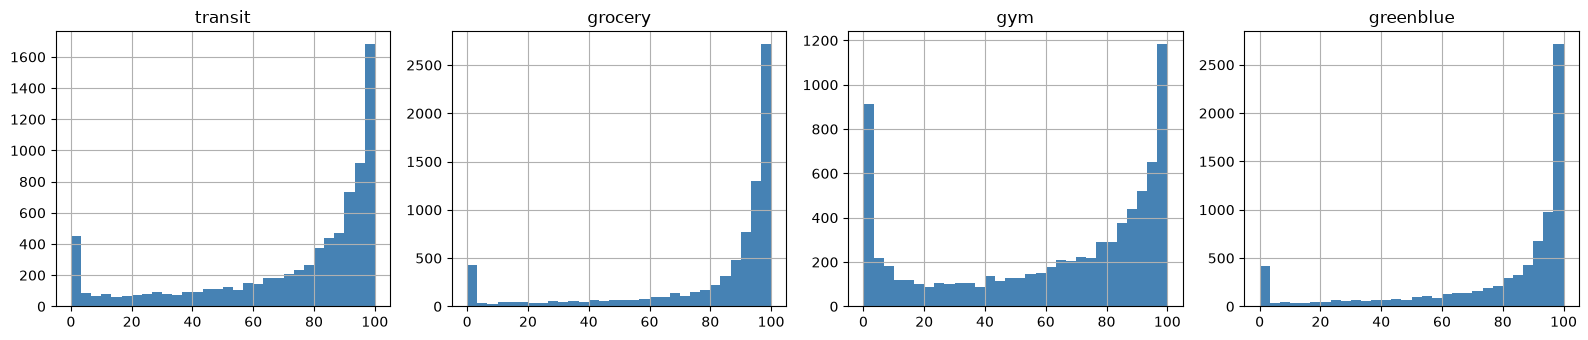

In [8]:
def logistic_decay(dist_m, threshold_m, k=DECAY_K):
    return 1 / (1 + np.exp(k * (dist_m - threshold_m) / threshold_m))

def winsorized_minmax(series, low=WINSOR_LOW, high=WINSOR_HIGH):
    lo, hi = series.quantile(low), series.quantile(high)
    clipped = series.clip(lo, hi)
    if hi == lo:
        return pd.Series(50.0, index=series.index)
    return (clipped - lo) / (hi - lo) * 100

proximity_factors = []
for name, threshold in DECAY_THRESHOLDS_M.items():
    decay = logistic_decay(buildings[f"{name}_dist_m"], threshold)
    buildings[f"{name}_score_norm"] = winsorized_minmax(decay)
    proximity_factors.append(f"{name}_score_norm")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, DECAY_THRESHOLDS_M):
    buildings[f"{name}_score_norm"].hist(ax=ax, bins=30, color="steelblue")
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 9. Check factor correlations (diagnostic)

`building_quality_score` isn't part of the final aggregation (see §10), but
it's still worth checking against the 4 scored factors — this is the check
that originally surfaced the negative correlation between building quality
and proximity in central Tallinn, which is exactly why energy data can't
be silently combined with the rest without distorting comparisons (see §10).


In [9]:
all_factors = ["building_quality_score"] + proximity_factors
corr = buildings[all_factors].corr()
print(corr.round(2))


                        building_quality_score  transit_score_norm  \
building_quality_score                    1.00               -0.11   
transit_score_norm                       -0.11                1.00   
grocery_score_norm                       -0.21                0.34   
gym_score_norm                           -0.16                0.14   
greenblue_score_norm                      0.11               -0.04   

                        grocery_score_norm  gym_score_norm  \
building_quality_score               -0.21           -0.16   
transit_score_norm                    0.34            0.14   
grocery_score_norm                    1.00            0.35   
gym_score_norm                        0.35            1.00   
greenblue_score_norm                 -0.21           -0.24   

                        greenblue_score_norm  
building_quality_score                  0.11  
transit_score_norm                     -0.04  
grocery_score_norm                     -0.21  
gym_score_norm    

## 10. Final aggregation: geometric mean + Mazziotta-Pareto (4 proximity factors)

**Why energy score isn't scored.** Energy performance and construction/
renovation timeline were both originally planned as scoring factors (see
the methodology doc's "what we wanted but couldn't integrate" note). Two
things ruled them out:

- **Data unavailability**: only 48.5% of buildings have a real energy
  certificate, and no true renovation-date field exists anywhere in the
  available data (only construction year, which notebook 2 showed is a
  weak, non-monotonic quality signal for ~90% of the stock).
- **Complexity/fairness**: excluding the factor per-building and
  renormalizing (tried in an earlier version of this notebook) produced a
  distorting side effect — buildings without energy data averaged a
  *higher* final score than buildings with it, because building quality is
  negatively correlated with proximity in Tallinn (§9), so skipping it
  quietly favored the buildings missing data. Imputing a value instead
  would have the opposite problem: presenting a model guess as if it were
  measured.

Rather than either compromise, `building_quality_score` is computed (see
notebook 2) and shown on the map/in attributes for reference, but is
**excluded from the score entirely**. Every building is now scored on
exactly the same 4 proximity factors — no adaptive weighting, no asymmetry
between buildings.

Two aggregation methods computed side by side as a sensitivity check:

- **Geometric mean**: partially non-compensatory, bounded 0-100, floored at
  1 to avoid a hard zero from forcing the whole product to zero.
- **Mazziotta-Pareto Index (adapted)**: `mean - variance/mean` -- penalizes
  imbalance across factors even when the average is high, per Higgs et al.
  2019's exact approach for the Melbourne ULI. Can go slightly negative for
  a very imbalanced factor profile -- diagnostic/ranking tool, not a
  displayed 0-100 score.


Spearman rank correlation between geomean and MPI scores: 0.994
                       count       mean        std       min        25%  \
has_building_quality                                                      
False                 4035.0  62.333100  26.839405  1.931212  41.420673   
True                  3807.0  62.850273  27.046998  1.937506  40.059636   

                            50%        75%        max  
has_building_quality                                   
False                 70.228483  84.774128  99.985540  
True                  71.178022  85.841412  99.809566  


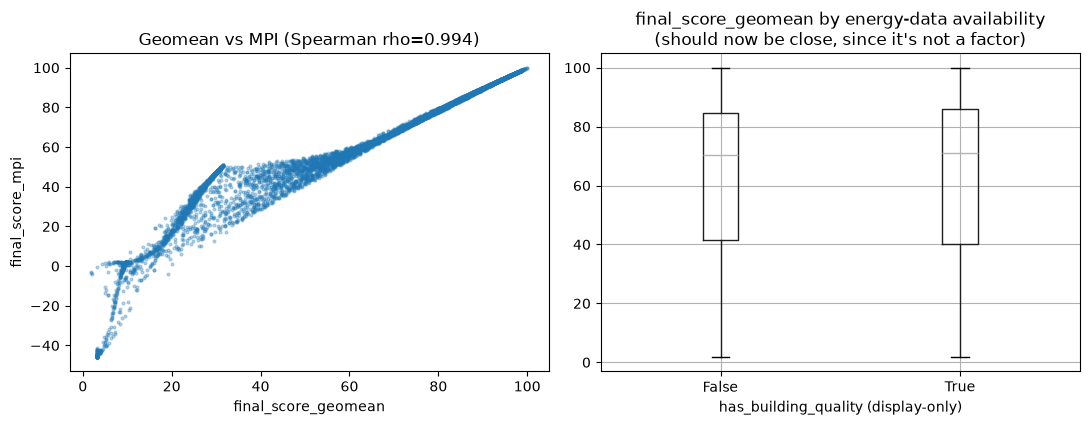

In [10]:
FLOOR = 1.0
factor_matrix = buildings[proximity_factors].clip(lower=FLOOR)   # 4 columns, always populated

buildings["has_building_quality"] = buildings["building_quality_score"].notna()  # display-only flag

# Geometric mean over the 4 proximity factors -- every building, same basis
buildings["final_score_geomean"] = np.exp(np.log(factor_matrix).mean(axis=1))

# Mazziotta-Pareto penalized mean, same 4 factors
row_mean = factor_matrix.mean(axis=1)
row_var = factor_matrix.var(axis=1, ddof=0)
buildings["final_score_mpi"] = row_mean - (row_var / row_mean)

rho, _ = spearmanr(buildings["final_score_geomean"], buildings["final_score_mpi"])
print(f"Spearman rank correlation between geomean and MPI scores: {rho:.3f}")

# Confirm energy-data availability no longer skews the final score now that
# it's excluded -- this should show a MUCH smaller gap than the earlier
# adaptive-weighting version did.
print(buildings.groupby("has_building_quality")["final_score_geomean"].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(buildings["final_score_geomean"], buildings["final_score_mpi"], s=4, alpha=0.3)
axes[0].set_xlabel("final_score_geomean")
axes[0].set_ylabel("final_score_mpi")
axes[0].set_title(f"Geomean vs MPI (Spearman rho={rho:.3f})")

buildings.boxplot(column="final_score_geomean", by="has_building_quality", ax=axes[1])
axes[1].set_title("final_score_geomean by energy-data availability\n(should now be close, since it's not a factor)")
axes[1].set_xlabel("has_building_quality (display-only)")
plt.suptitle("")
plt.tight_layout()
plt.show()


## 11. Data-driven livability categories

Bins `final_score_geomean` into categories using **Jenks natural breaks**
(`mapclassify.NaturalBreaks`), not arbitrary fixed cutoffs (e.g. "0-20 =
Very Low") — Jenks finds break points that minimize variance *within* each
category and maximize variance *between* categories, so the bins reflect
actual clusters in Tallinn's score distribution rather than an assumed
scale.


NaturalBreaks

   Interval      Count
----------------------
[ 1.93, 20.31] |   705
(20.31, 41.64] |  1284
(41.64, 63.54] |  1317
(63.54, 81.55] |  2008
(81.55, 99.99] |  2528


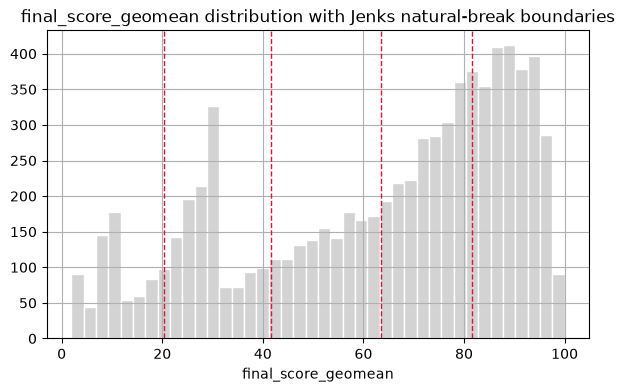


livability_category
Very Low      705
Low          1284
Medium       1317
High         2008
Very High    2528
Name: count, dtype: int64


In [11]:
import mapclassify

N_CATEGORIES = 5
CATEGORY_LABELS = ["Very Low", "Low", "Medium", "High", "Very High"]

classifier = mapclassify.NaturalBreaks(buildings["final_score_geomean"], k=N_CATEGORIES)
print(classifier)

buildings["livability_category"] = pd.Categorical.from_codes(
    classifier.yb, categories=CATEGORY_LABELS, ordered=True
)

fig, ax = plt.subplots(figsize=(7, 4))
buildings["final_score_geomean"].hist(ax=ax, bins=40, color="lightgray", edgecolor="white")
for b in classifier.bins[:-1]:
    ax.axvline(b, color="crimson", linestyle="--", linewidth=1)
ax.set_title("final_score_geomean distribution with Jenks natural-break boundaries")
ax.set_xlabel("final_score_geomean")
plt.show()

print()
print(buildings["livability_category"].value_counts().sort_index())


## 12. Interactive map

Building-level map: fill color = livability category (based purely on the
4 proximity factors). Energy data is **display-only** here — shown in the
tooltip (actual letter grade, or "Not available") and via a faded
fill + dashed outline for buildings without a certificate — but it has no
effect on the color/category/score itself, since it's not part of the
scoring (§10).

Saved as a standalone HTML file (not published as a shareable link) because
it uses live OpenStreetMap/CartoDB basemap tiles, which need network
access each time it's viewed — open it locally in a browser.


In [12]:
import folium

buildings_4326 = buildings.to_crs(4326).copy()

# Colorblind-safe-ish sequential palette, worst -> best
CATEGORY_COLORS = {
    "Very Low":  "#d73027",
    "Low":       "#fc8d59",
    "Medium":    "#fee08b",
    "High":      "#91cf60",
    "Very High": "#1a9850",
}

buildings_4326["fill_color"] = buildings_4326["livability_category"].astype(str).map(CATEGORY_COLORS)
buildings_4326["address_display"] = buildings_4326["ads_lahiaadress"].fillna(buildings_4326["taisaadress"])
buildings_4326["score_display"] = buildings_4326["final_score_geomean"].round(1)
buildings_4326["category_display"] = buildings_4326["livability_category"].astype(str)
# Actual letter grade where known, explicit "Not available" otherwise -- not just Yes/No
buildings_4326["energy_display"] = buildings_4326["energiaklass"].fillna("Not available")

def style_function(feature):
    has_energy = feature["properties"]["has_building_quality"]
    return {
        "fillColor": feature["properties"]["fill_color"],
        "color": "#333333" if has_energy else "#999999",
        "weight": 0.6,
        "dashArray": None if has_energy else "3,2",
        "fillOpacity": 0.75 if has_energy else 0.35,
    }

m = folium.Map(location=[59.437, 24.7536], zoom_start=12, tiles="cartodbpositron", prefer_canvas=True)

cols = ["geometry", "address_display", "score_display", "category_display", "energy_display",
        "fill_color", "has_building_quality"]
folium.GeoJson(
    buildings_4326[cols],
    style_function=style_function,
    tooltip=folium.GeoJsonTooltip(
        fields=["address_display", "score_display", "category_display", "energy_display"],
        aliases=["Address:", "Livability score (0-100):", "Category:", "Energy class (reference only):"],
        sticky=True,
    ),
).add_to(m)

legend_rows = "".join(
    f'<span style="display:inline-block;width:12px;height:12px;background:{c};margin-right:6px;"></span>{lbl}<br>'
    for lbl, c in CATEGORY_COLORS.items()
)
legend_html = f"""
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 10px 14px; border: 1px solid #999; border-radius: 4px; font-size: 13px;
            font-family: sans-serif; line-height: 1.5;">
  <b>Livability category</b><br>
  {legend_rows}
  <hr style="margin:6px 0;">
  <span style="display:inline-block;width:12px;height:12px;border:1px dashed #999;margin-right:6px;"></span>
  No energy certificate on file (display only -- does not affect score)
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

OUTPUT_HTML = Path("tallinn_livability_map.html")
m.save(str(OUTPUT_HTML))
print(f"Saved interactive map -> {OUTPUT_HTML.resolve()}")
print("Open it locally in a browser (double-click the file).")


Saved interactive map -> /Users/vignapurohit/Desktop/livability_score/tallinn_livability_map.html
Open it locally in a browser (double-click the file).


## 13. Save


In [13]:
buildings.to_file(OUTPUT_GPKG, layer=OUTPUT_LAYER, driver="GPKG")
print(f"Saved -> {OUTPUT_GPKG}, layer '{OUTPUT_LAYER}' ({len(buildings):,} buildings)")

new_cols = [c for c in buildings.columns if any(
    c.startswith(p) for p in ["transit_", "grocery_", "gym_", "greenblue_", "final_score",
                               "has_building_quality", "livability_category"]
)]
print("New columns:", new_cols)


Saved -> data/tallinn_livability_base.gpkg, layer 'buildings_final_score' (7,842 buildings)
New columns: ['transit_dist_m', 'transit_reachable', 'grocery_dist_m', 'grocery_reachable', 'gym_dist_m', 'gym_reachable', 'greenblue_dist_m', 'greenblue_reachable', 'transit_score_norm', 'grocery_score_norm', 'gym_score_norm', 'greenblue_score_norm', 'has_building_quality', 'final_score_geomean', 'final_score_mpi', 'livability_category']


## Next steps

- **Sensitivity analysis**: Monte Carlo over weighting schemes, decay
  parameters (`k`, category thresholds), and normalization method -- see
  notebook 4.
- **Expert/local weighting**: elicit Tallinn-specific weights via a short
  AHP or Delphi survey (per Norouzian-Maleki et al.'s Estonian precedent)
  and compare against the equal-weight default used here.
- **Diversity term**: currently only nearest-amenity distance counts: a
  building near five groceries scores the same as one near exactly one.
  Consider adding a count/diversity term within the decay radius.
- **Energy score and renovation timeline were intentionally left out of
  the score** — data unavailability (only 48.5% certified, no true
  renovation-date field anywhere) and the fairness/complexity problems
  documented in §10, not an oversight. If a better EHR crosswalk, export,
  or renovation-date source surfaces later, this is the natural place to
  revisit it. Full reasoning is in the published methodology document.
